In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [6]:
# Load the cleaned dataset

df = pd.read_parquet("../data/clean.parquet")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (2198955, 70)


In [7]:
# Separate input features and target labels

X = df.drop(columns=["Group"])

y = df["Group"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (2198955, 69)
Labels shape: (2198955,)


In [19]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1759164, 69)
Testing features: (439791, 69)
Training labels: (1759164,)
Testing labels: (439791,)


In [10]:
# Check training category distribution

print("Training category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training category distribution:
Group
BENIGN        1490020
DoS            154984
DDoS           102411
BruteForce       7320
WebAttack        1714
PortScan         1565
Bot              1150
Name: count, dtype: int64

Testing category distribution:
Group
BENIGN        372505
DoS            38746
DDoS           25603
BruteForce      1830
WebAttack        429
PortScan         391
Bot              287
Name: count, dtype: int64


In [11]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import time

In [12]:
rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

t = time.time()

rf.fit(X_train, y_train)

print("RF trained in", round(time.time() - t), "seconds")

RF trained in 112 seconds


In [13]:
hgb = HistGradientBoostingClassifier(
    random_state=42
)

t = time.time()

hgb.fit(X_train, y_train)

print("HGB trained in", round(time.time() - t), "seconds")

HGB trained in 36 seconds


In [14]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [20]:
rf_pred = rf.predict(X_test)
hgb_pred = hgb.predict(X_test)

print("Both models have generated predictions successfully!")

Both models have generated predictions successfully!


In [16]:
rf_accuracy = accuracy_score(y_test, rf_pred)
hgb_accuracy = accuracy_score(y_test, hgb_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("HistGradientBoosting Accuracy:", round(hgb_accuracy * 100, 2), "%")

Random Forest Accuracy: 99.49 %
HistGradientBoosting Accuracy: 99.76 %


In [12]:
print("========== RANDOM FOREST ==========")
print(classification_report(y_test, rf_pred))

print("\n========== HIST GRADIENT BOOSTING ==========")
print(classification_report(y_test, hgb_pred))

========== RANDOM FOREST ==========
              precision    recall  f1-score   support

      BENIGN       1.00      0.99      1.00    372505
         Bot       0.14      0.98      0.25       287
  BruteForce       0.98      1.00      0.99      1830
        DDoS       1.00      1.00      1.00     25603
         DoS       0.99      1.00      1.00     38746
    PortScan       0.92      0.97      0.95       391
   WebAttack       0.90      0.98      0.94       429

    accuracy                           0.99    439791
   macro avg       0.85      0.99      0.87    439791
weighted avg       1.00      0.99      1.00    439791


========== HIST GRADIENT BOOSTING ==========
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    372505
         Bot       0.58      0.53      0.55       287
  BruteForce       0.99      0.99      0.99      1830
        DDoS       1.00      1.00      1.00     25603
         DoS       1.00      0.99      0.99     38

In [21]:
from sklearn.metrics import confusion_matrix

# Convert multiclass labels into BENIGN vs ATTACK
y_binary = (y_test != "BENIGN").astype(int)
pred_binary = (rf_pred != "BENIGN").astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_binary,
    pred_binary,
    labels=[0, 1]
).ravel()

print("RANDOM FOREST - RANDOM SPLIT")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)
print("False Positive Rate:", round(fp / (fp + tn), 6))

RANDOM FOREST - RANDOM SPLIT
TN: 370339
FP: 2166
FN: 54
TP: 67232
False Positive Rate: 0.005815


In [14]:
import pandas as pd

rf_report = classification_report(
    y_test, rf_pred, output_dict=True
)

hgb_report = classification_report(
    y_test, hgb_pred, output_dict=True
)

categories = [
    "BENIGN",
    "Bot",
    "BruteForce",
    "DDoS",
    "DoS",
    "PortScan",
    "WebAttack"
]

comparison = pd.DataFrame({
    "RF Precision": {
        category: rf_report[category]["precision"]
        for category in categories
    },
    "RF Recall": {
        category: rf_report[category]["recall"]
        for category in categories
    },
    "RF F1": {
        category: rf_report[category]["f1-score"]
        for category in categories
    },
    "HGB Precision": {
        category: hgb_report[category]["precision"]
        for category in categories
    },
    "HGB Recall": {
        category: hgb_report[category]["recall"]
        for category in categories
    },
    "HGB F1": {
        category: hgb_report[category]["f1-score"]
        for category in categories
    }
})

print(comparison.round(3))

            RF Precision  RF Recall  RF F1  HGB Precision  HGB Recall  HGB F1
BENIGN             1.000      0.994  0.997          0.998       0.999   0.999
Bot                0.143      0.983  0.250          0.580       0.530   0.554
BruteForce         0.977      0.996  0.987          0.989       0.989   0.989
DDoS               0.999      1.000  0.999          0.999       0.999   0.999
DoS                0.991      0.999  0.995          0.996       0.989   0.993
PortScan           0.918      0.974  0.945          0.804       0.936   0.865
WebAttack          0.898      0.981  0.938          0.888       0.928   0.908


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

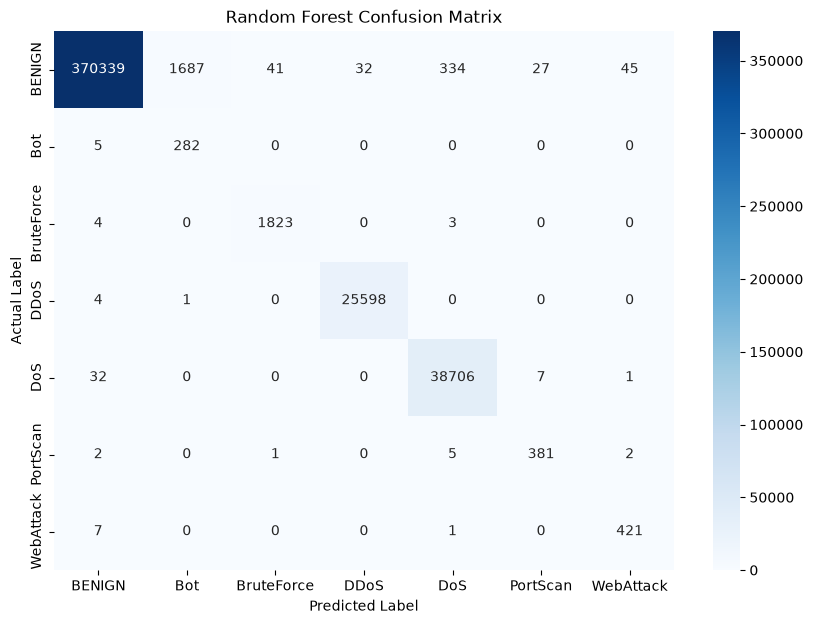

In [16]:
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf.classes_,
    yticklabels=rf.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

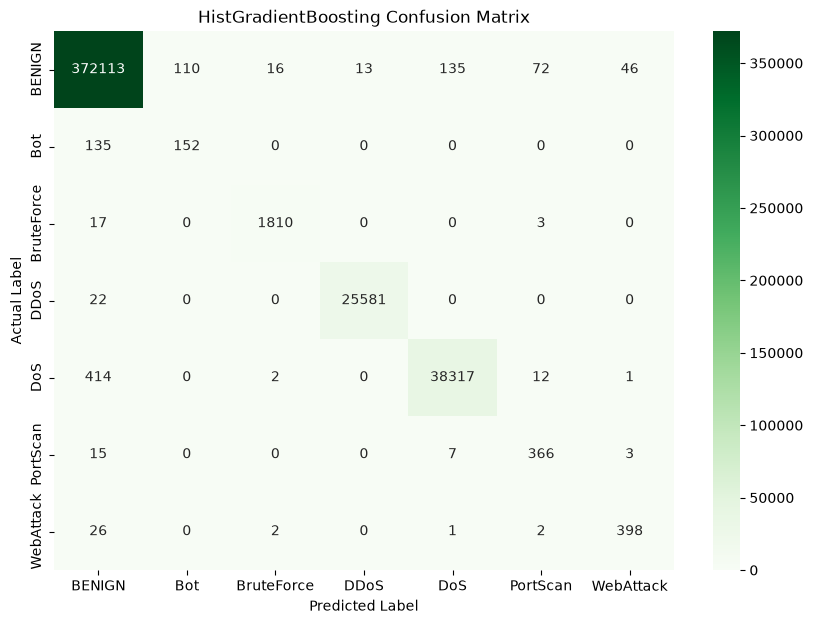

In [17]:
hgb_cm = confusion_matrix(y_test, hgb_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    hgb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=hgb.classes_,
    yticklabels=hgb.classes_
)

plt.title("HistGradientBoosting Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [18]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(rf, "../models/random_forest.pkl")
joblib.dump(hgb, "../models/hist_gradient_boosting.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [3]:
import json
import joblib
from pathlib import Path

# Load the previously trained Random Forest model
rf = joblib.load("../models/random_forest.pkl")

print("Random Forest model loaded successfully!")

# Create the backend model directory
backend_model_dir = Path("../backend/models")
backend_model_dir.mkdir(parents=True, exist_ok=True)

# Save the model using the filename expected by the backend
joblib.dump(
    rf,
    backend_model_dir / "ids_rf.joblib"
)

# Extract the exact feature names and their order
features = list(rf.feature_names_in_)

# Save the feature names as JSON
with open(backend_model_dir / "features.json", "w") as f:
    json.dump(features, f, indent=4)

print("Backend model exported successfully!")
print("Number of features:", len(features))
print("Model file exists:", (backend_model_dir / "ids_rf.joblib").exists())
print("Features file exists:", (backend_model_dir / "features.json").exists())

Random Forest model loaded successfully!
Backend model exported successfully!
Number of features: 69
Model file exists: True
Features file exists: True


In [22]:
from sklearn.metrics import classification_report, accuracy_score

rf_report = classification_report(
    y_test,
    rf_pred,
    output_dict=True,
    zero_division=0
)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Macro precision:", round(rf_report["macro avg"]["precision"], 4))
print("Macro recall:", round(rf_report["macro avg"]["recall"], 4))
print("Macro F1:", round(rf_report["macro avg"]["f1-score"], 4))

Accuracy: 0.9949
Macro precision: 0.8466
Macro recall: 0.9896
Macro F1: 0.873
